# 🦅 APT + Reverse Layer-Wise PPF (Reverse L-PPF: α = 0.55 → 0.85) — Đa Bộ Dữ Liệu (Multi-Dataset: CIFAR-100, Stanford Cars-196, ImageNet-R, CUB-200)

## 📌 Bối cảnh & Mục tiêu Nghiên cứu (Negative Control / Sanity Check Ablation)
Notebook này mở rộng thực nghiệm phản nghiệm đối chứng (**Negative Control Ablation Study**) trên **3 bộ dữ liệu Continual Learning**:
1. **CIFAR-100** (100 lớp — 10 Tasks × 10 lớp | Train: 50,000 ảnh, Test: 10,000 ảnh)
2. **Stanford Cars-196** (196 lớp — 10 Tasks: Task 1 gồm 16 lớp + 9 Tasks × 20 lớp | Train: 8,144 ảnh, Test: 8,041 ảnh)
3. **ImageNet-R** (200 lớp — 10 Tasks × 20 lớp | Train: 24,000 ảnh, Test: 6,000 ảnh)
*(Tùy chọn: Có thể bật chạy lại **CUB-200-2011** với 200 lớp — 10 Tasks × 20 lớp).*

---

### 🧠 Câu hỏi Nghiên cứu & Giả thuyết Khoa học (Hypothesis)
* **Câu hỏi cốt lõi**: *"Liệu sự vượt trội của Hierarchical Layer-Wise PPF (L-PPF) có thực sự đến từ hướng phân tầng: Bảo thủ ở tầng nông ($\alpha=0.85$) và Dẻo dai ở tầng sâu ($\alpha=0.55$)? Hay bất kỳ sự phân bổ gradient nào qua các tầng cũng mang lại kết quả như nhau?"*
* **Thiết kế Reverse L-PPF (Đảo ngược phân tầng)**:
  - **Tầng nông (Layer 0 – 3)**: Đặt $\alpha = 0.55$ (giảm khả năng giữ tri thức cũ, tăng biến động $\to$ dự đoán: **tỷ lệ quên $F_T$ tăng vọt** do Low-level Representation Drift).
  - **Tầng sâu (Layer 8 – 11)**: Đặt $\alpha = 0.85$ (quá bảo thủ, chỉ nhận $15\%$ gradient mới $	o$ dự đoán: **mất khả năng thích ứng với các class mới**, $R_{t,t}$ tụt dốc).
  - **Giá trị trung bình**: Vẫn giữ nguyên tuyệt đối $\bar{\alpha} = \frac{0.55 + 0.85}{2} = 0.70$ (đảm bảo tính công bằng 100% với Uniform PPF $\alpha=0.70$ và Standard L-PPF $0.85 \to 0.55$).
* **Kết luận kỳ vọng**: Hiệu năng Reverse L-PPF sẽ tụt dốc trên cả 3 dataset so với Standard L-PPF, chứng minh bằng thực nghiệm rằng định lý *"Tầng nông giữ nét thô - Tầng sâu tiếp nhận ngữ nghĩa mới"* là quy luật phổ quát trong Vision Transformer!

---

### 🧪 Giao thức Dữ liệu Chuẩn (`check-dataset.ipynb`)
* **Stratified Disjoint 5-Fold (Val Split - Giai đoạn 1)**:
  - Chia 80% Train, 20% Val qua 3 seed `0, 1, 2` (`base_seed = 1993`).
  - Đảm bảo 0% Validation Overlap giữa các seed.
  - Niêm phong 100% tập Test chính thức để loại bỏ nguy cơ Data Leakage.
* **Hỗ trợ Task Sizes Biến thiên**: Xử lý chính xác Task 1 gồm 16 lớp của Cars-196 và 10/20 lớp của CIFAR-100 / ImageNet-R.

## 1. Cài đặt Môi trường & Thư viện
* Kích hoạt `line_buffering=True` để log hiển thị tức thì trên Kaggle Console.
* Tự động cài đặt `timm` nếu chưa có.
* Tối ưu hóa TF32 & cuDNN trên GPU T4/P100.

In [1]:
import os, sys, json, time, math, random, subprocess, pickle, warnings
warnings.filterwarnings("ignore")

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from PIL import Image

print(f"torch {torch.__version__} | timm {timm.__version__}", flush=True)
assert torch.cuda.is_available(), "⚠️ Chưa bật GPU: Hãy vào Settings → Accelerator → GPU T4 x2 (hoặc GPU P100)"
DEVICE = "cuda"
print(f"✅ GPU đang hoạt động: {torch.cuda.get_device_name(0)}", flush=True)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

torch 2.11.0+cu128 | timm 1.0.29
✅ GPU đang hoạt động: Tesla T4


## 2. Cấu hình Thực nghiệm Đa Bộ Dữ Liệu (`DATASET_CONFIGS` & `GLOBAL_CFG`)
* Cấu hình Reverse L-PPF: `ppf_mode="layer_wise"`, `alpha_range=(0.55, 0.85)` (Shallow=0.55, Deep=0.85, Mean=0.70).
* Cấu hình Hybrid Head: `tau=2.0`, `alpha=1.5`, `kac_num_grids=4`.
* `ACTIVE_DATASETS`: Lựa chọn các dataset muốn chạy trong phiên thực nghiệm này.

In [2]:
# ==============================================================================
# CẤU HÌNH DANH SÁCH DATASET MUỐN CHẠY
# Bạn có thể chọn bất kỳ tổ hợp nào: ["cifar100", "cars196", "imagenet_r"] (hoặc thêm "cub200")
# ==============================================================================
ACTIVE_DATASETS = ["cifar100", "cars196", "imagenet_r"]

DATASET_CONFIGS = {
    "cifar100": {
        "name": "CIFAR-100",
        "data_type": "cifar_pickle",
        "n_classes": 100,
        "n_tasks": 10,
        "task_sizes": [10] * 10,       # 10 tasks x 10 classes = 100 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/thohintrnhngc/cifar-100-python/cifar-100-python",
            "/kaggle/input/cifar-100-python/cifar-100-python",
            "/kaggle/input/cifar100/cifar-100-python",
            "/kaggle/input/cifar-100-python",
            "data/cifar-100-python",
        ],
    },
    "cars196": {
        "name": "Stanford Cars-196",
        "data_type": "image_folder",
        "n_classes": 196,
        "n_tasks": 10,
        "task_sizes": [16] + [20] * 9,  # Task 1 (16 lớp) + 9 Tasks (20 lớp) = 196 lớp
        "epochs": 20,
        "batch_size": 64,               # 64 batch size phù hợp cho Cars
        "prompt_lr": 0.01,
        "cos_head_lr": 0.01,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder/car_data/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder/car_data",
            "/kaggle/input/stanford-car-dataset-by-classes-folder",
            "data/cars",
        ],
    },
    "imagenet_r": {
        "name": "ImageNet-R",
        "data_type": "image_folder",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/thohintrnhngc/imagenet-r",
            "/kaggle/input/imagenet-r/imagenet-r",
            "/kaggle/input/imagenet-r",
            "data/imagenet-r",
        ],
    },
    "cub200": {
        "name": "CUB-200-2011",
        "data_type": "image_folder",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
        "candidates": [
            "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
            "/kaggle/input/cub-200-2011/CUB_200_2011/images",
            "/kaggle/input/cub2002011/CUB_200_2011/images",
            "/kaggle/input/cub200/CUB_200_2011/images",
        ],
    }
}

GLOBAL_CFG = dict(
    seeds=[0, 1, 2],                 # 3 fold val độc lập (0% overlap)
    phases=["val"],                  # Giai đoạn 1: kiểm định trên 20% Val
    ppf_mode="layer_wise",           # "layer_wise" (với alpha_range đảo ngược)
    alpha_range=(0.55, 0.85),        # ĐẢO NGƯỢC: shallow=0.55 (lỏng lẻo), deep=0.85 (cứng nhắc), Mean = 0.70
    ema_coeff=0.70,                  # Fallback khi ppf_mode="uniform"
    tau=2.0,                         # Temperature scaling cho Cosine Head
    alpha=1.5,                       # Trọng số kết hợp KAC Head
    kac_num_grids=4,                 # 4 knot grids theo KAC paper (CVPR 2025)
    kac_grid_range=(-2.0, 2.0),
    use_amp=True,                    # Mixed Precision FP16
    num_workers=2,                   # Tối ưu cho Kaggle 2 vCPUs
    max_train_batches=None,          # Giới hạn số batch mỗi epoch (None: toàn bộ)
    base_out_dir="/kaggle/working/outputs_apt_reverse_lppf_3datasets",
    timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
)

DEBUG = False   # True: chạy test luồng nhanh 2 task x 1 epoch với 3 batch
if DEBUG:
    GLOBAL_CFG.update(seeds=[0], phases=["val"], max_train_batches=3)
    for k in DATASET_CONFIGS:
        DATASET_CONFIGS[k]["epochs"] = 1
        DATASET_CONFIGS[k]["n_tasks"] = 2
        DATASET_CONFIGS[k]["task_sizes"] = DATASET_CONFIGS[k]["task_sizes"][:2]

os.makedirs(GLOBAL_CFG["base_out_dir"], exist_ok=True)
print("Các dataset được chọn chạy:", ACTIVE_DATASETS, flush=True)

Các dataset được chọn chạy: ['cifar100', 'cars196', 'imagenet_r']


## 3. Quản lý Dữ liệu Đa Nguồn & Giao thức Chia Train / Val Chuẩn
* **CIFAR-100**: Đọc trực tiếp pickle từ `CIFAR100PickleDataset`.
* **Cars-196 & ImageNet-R**: Quét tự động cấu trúc thư mục với `ImageFolder`.
* **Universal Stratified Disjoint 5-Fold**: Chia 80% Train / 20% Val cho từng class với `base_seed = 1993`.

In [3]:
class CIFAR100PickleDataset(Dataset):
    """Đọc trực tiếp file pickle train/test/meta có sẵn trên Kaggle (không cần tải lại)."""
    def __init__(self, root, train=True, transform=None):
        self.root = root
        self.transform = transform
        split_file = "train" if train else "test"
        with open(os.path.join(root, split_file), "rb") as f:
            entry = pickle.load(f, encoding="latin1")
        with open(os.path.join(root, "meta"), "rb") as f:
            meta = pickle.load(f, encoding="latin1")
        self.data = entry["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)  # (N, 32, 32, 3) uint8
        self.targets = [int(y) for y in entry["fine_labels"]]
        self.classes = list(meta["fine_label_names"])

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        img = Image.fromarray(self.data[idx])
        if self.transform is not None:
            img = self.transform(img)
        return img, self.targets[idx]

def detect_dataset_root(ds_key):
    cfg = DATASET_CONFIGS[ds_key]
    candidates = cfg["candidates"]
    for path in candidates:
        if os.path.exists(path):
            if cfg["data_type"] == "cifar_pickle":
                if os.path.isfile(os.path.join(path, "train")):
                    return path
            else:
                if os.path.isdir(os.path.join(path, "train")):
                    return path
                subdirs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
                if len(subdirs) >= cfg["n_classes"]:
                    return path
    raise FileNotFoundError(f"Không tìm thấy dataset '{cfg['name']}'! Hãy kiểm tra Add Data trên Kaggle với các đường dẫn: {candidates}")

def load_raw_dataset(ds_key):
    root = detect_dataset_root(ds_key)
    cfg = DATASET_CONFIGS[ds_key]
    print(f"✅ Đã nhận diện {cfg['name']} tại: {root}", flush=True)
    if cfg["data_type"] == "cifar_pickle":
        train_ds = CIFAR100PickleDataset(root, train=True)
        test_ds  = CIFAR100PickleDataset(root, train=False)
    else:
        train_path = os.path.join(root, "train") if os.path.isdir(os.path.join(root, "train")) else root
        test_path  = os.path.join(root, "test") if os.path.isdir(os.path.join(root, "test")) else root
        train_ds = ImageFolder(train_path)
        test_ds  = ImageFolder(test_path)
    return train_ds, test_ds

def setup_continual_seed(train_dataset, seed, num_classes, task_sizes, n_splits=5, base_seed=1993):
    assert 0 <= seed < n_splits, f"seed phải nằm trong [0, {n_splits-1}]"
    
    # (a) Đảo thứ tự class vào các Tasks theo seed
    rng_task = np.random.RandomState(seed)
    class_order = rng_task.permutation(num_classes).tolist()
    task_classes, cur = [], 0
    for sz in task_sizes:
        task_classes.append(class_order[cur : cur + sz])
        cur += sz

    # (b) Chia Stratified Disjoint 5-Fold bên trong từng class -> lấy Fold[seed] làm Val (20%)
    targets = np.asarray(train_dataset.targets)
    tr_idx, va_idx = [], []
    rng_split = np.random.RandomState(base_seed)
    for c in range(num_classes):
        c_indices = np.where(targets == c)[0]
        perm = rng_split.permutation(c_indices)
        folds = np.array_split(perm, n_splits)
        va_idx.extend(folds[seed])
        for k in range(n_splits):
            if k != seed:
                tr_idx.extend(folds[k])

    return task_classes, np.array(tr_idx), np.array(va_idx)

def get_task_subsets(train_dataset, test_dataset, task_classes, tr_idx, va_idx, task_id, phase="val"):
    cur_cls = set(task_classes[task_id])
    seen_cls = set(sum(task_classes[: task_id + 1], []))
    tr_targets = np.asarray(train_dataset.targets)

    if phase == "val":
        t_tr_idx = [i for i in tr_idx if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in va_idx if tr_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(train_dataset, t_ev_idx)
    elif phase == "test":
        te_targets = np.asarray(test_dataset.targets)
        t_tr_idx = [i for i in range(len(tr_targets)) if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in range(len(te_targets)) if te_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(test_dataset, t_ev_idx)
    else:
        raise ValueError("phase phải là 'val' hoặc 'test'")

TRAIN_TF = T.Compose([
    T.AutoAugment(T.AutoAugmentPolicy.IMAGENET, T.InterpolationMode.BILINEAR),
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
])
TEST_TF = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
])

class RemapTransformDataset(Dataset):
    def __init__(self, subset, transform, remap):
        self.subset = subset
        self.transform = transform
        self.remap = remap

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, y = self.subset[idx]
        if self.transform is not None:
            img = self.transform(img)
        new_y = self.remap[y] if self.remap is not None else y
        return img, new_y

## 4. Kiến trúc Mô hình: ViT-B/16 + APT Prompt (Reverse L-PPF) + Hybrid Classifier
* **APTPrompt với Reverse L-PPF**: Phân bổ $\alpha_l$ đảo ngược từ $0.55$ (tầng nông) tăng dần lên $0.85$ (tầng sâu).
* **Hybrid Classifier Head**:
  - `CosineHead`: LayerNorm không affine + Linear chuẩn hóa L2 weight.
  - `KACHead`: Gaussian RBF Spline $N=4$ knots trên feature đã detach (`f.detach()`).

In [4]:
# ---------------- ViT-B/16 (frozen) có hook cho Additive Prompt ----------------
class PatchEmbed(nn.Module):
    def __init__(self, dim=768, patch=16):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.heads, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, prompt=None):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, self.hd).permute(2, 0, 3, 1, 4).unbind(0)
        if prompt is not None:
            pk, pv = prompt
            k = torch.cat([k[:, :, :1] + pk.to(k.dtype), k[:, :, 1:]], dim=2)
            v = torch.cat([v[:, :, :1] + pv.to(v.dtype), v[:, :, 1:]], dim=2)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Module):
    def __init__(self, dim=768, hidden=3072):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

class Block(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, dim * 4)

    def forward(self, x, prompt=None):
        x = x + self.attn(self.norm1(x), prompt)
        x = x + self.mlp(self.norm2(x))
        return x

class ViT(nn.Module):
    def __init__(self, dim=768, depth=12, heads=12):
        super().__init__()
        self.depth, self.heads = depth, heads
        self.patch_embed = PatchEmbed(dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, dim))
        self.blocks = nn.ModuleList([Block(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, eps=1e-6)

    def forward(self, x, prompt_fn=None):
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + self.pos_embed
        for i, blk in enumerate(self.blocks):
            x = blk(x, prompt_fn(i) if prompt_fn is not None else None)
        return self.norm(x)[:, 0]          # CLS feature

def load_pretrained_vit(name):
    try:
        ref = timm.create_model(name, pretrained=True, num_classes=0)
    except Exception as e:
        print(f"[warn] không tải được {name} ({e}); thử 'vit_base_patch16_224'", flush=True)
        ref = timm.create_model("vit_base_patch16_224", pretrained=True, num_classes=0)
    sd = {k: v for k, v in ref.state_dict().items() if not k.startswith("head")}
    vit = ViT()
    missing, unexpected = vit.load_state_dict(sd, strict=False)
    assert not missing, f"Thiếu key backbone: {missing}"
    if unexpected:
        print("[info] bỏ qua key:", unexpected, flush=True)
    for p in vit.parameters():
        p.requires_grad_(False)
    return vit.eval(), ref.eval()

# ---------------- APT Prompt với Reverse Layer-Wise PPF (Reverse L-PPF) ----------------
class APTPrompt(nn.Module):
    """
    APTPrompt với cơ chế Reverse Layer-Wise PPF (Reverse L-PPF: 0.55 -> 0.85):
    - Tầng nông (Layer 0-3): alpha thấp (0.55) -> tăng biến động, giảm khả năng giữ tri thức.
    - Tầng sâu (Layer 8-11): alpha cao (0.85) -> quá bảo thủ, giảm khả năng thích ứng với class mới.
    - Phản nghiệm đối chứng để chứng minh tính đúng đắn của giả thuyết thiết kế L-PPF ban đầu!
    """
    def __init__(self, depth=12, dim=768, heads=12, ema_coeff=0.7, 
                 ppf_mode="layer_wise", alpha_range=(0.55, 0.85)):
        super().__init__()
        self.depth, self.heads, self.hd = depth, heads, dim // heads
        self.ppf_mode = ppf_mode
        self.alpha_range = alpha_range
        self.ema_coeff = ema_coeff
        
        # 12 tầng * 2 prompts [k_0, v_0, k_1, v_1, ...] = 24 vectors (dim=768)
        self.prompt_tokens = nn.Parameter(torch.zeros(depth * 2, dim))
        nn.init.trunc_normal_(self.prompt_tokens, std=0.02)
        self.register_buffer("merged", torch.zeros(depth * 2, dim))
        self.n_merged = 0
        self.use_merged = False
        
        # Tạo vector trọng số alpha đảo ngược cho từng vector prompt
        if ppf_mode == "layer_wise":
            a_shallow, a_deep = alpha_range
            alphas = torch.linspace(a_shallow, a_deep, depth) # (12,) từ 0.55 đến 0.85
            alphas_24 = alphas.repeat_interleave(2).unsqueeze(1) # shape (24, 1)
            self.register_buffer("layer_alphas", alphas_24)
        else:
            self.register_buffer("layer_alphas", torch.full((depth * 2, 1), ema_coeff))
            
    def get(self, l):
        P = self.merged if self.use_merged else self.prompt_tokens
        return P[2 * l].view(self.heads, 1, self.hd), P[2 * l + 1].view(self.heads, 1, self.hd)
        
    @torch.no_grad()
    def merge(self):
        if self.n_merged == 0:
            self.merged.copy_(self.prompt_tokens)
        else:
            a = self.layer_alphas
            self.merged.copy_(self.merged * a + self.prompt_tokens * (1.0 - a))
        self.n_merged += 1
        
        a_0 = self.layer_alphas[0].item()
        a_last = self.layer_alphas[-1].item()
        a_mean = self.layer_alphas.mean().item()
        print(f"  [Reverse L-PPF Merge #{self.n_merged}] mode={self.ppf_mode} | Layer 0 α={a_0:.3f} -> Layer 11 α={a_last:.3f} (Mean={a_mean:.3f})", flush=True)

# ---------------- Classifier heads ----------------
class CosineHead(nn.Module):
    def __init__(self, dim, n_cls):
        super().__init__()
        self.norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
    def forward(self, f):
        return self.norm(f) @ F.normalize(self.fc.weight, dim=1).t()

class KACHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0)):
        super().__init__()
        gmin, gmax = grid_range
        self.layernorm = nn.LayerNorm(dim)
        self.register_buffer("grid", torch.linspace(gmin, gmax, num_grids))
        self.denominator = (gmax - gmin) / (num_grids - 1)
        self.spline_linear = nn.Linear(dim * num_grids, n_cls, bias=False)
        nn.init.zeros_(self.spline_linear.weight)
    def forward(self, f):
        x = self.layernorm(f)
        basis = torch.exp(-((x[..., None] - self.grid) / self.denominator) ** 2)
        return self.spline_linear(basis.flatten(1))

class HybridHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5):
        super().__init__()
        self.cos_head = CosineHead(dim, n_cls)
        self.kac_head = KACHead(dim, n_cls, num_grids, grid_range)
        self.tau = tau
        self.alpha = alpha

    def forward(self, f):
        out_norm = self.cos_head.norm(f)
        logit_cos = self.cos_head(f)
        logit_kac = self.kac_head(f.detach())   # Detach KAC để bảo toàn representation của prompt
        if self.training:
            return logit_cos, logit_kac
        else:
            return logit_cos, logit_kac, out_norm

class APTHybridReverseLPPFNet(nn.Module):
    def __init__(self, vit, n_cls, ppf_mode="layer_wise", alpha_range=(0.55, 0.85), ema_coeff=0.7, 
                 kac_num_grids=4, kac_grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5, use_amp=True):
        super().__init__()
        self.vit = vit
        self.prompt = APTPrompt(
            vit.depth, 768, vit.heads, ema_coeff=ema_coeff,
            ppf_mode=ppf_mode, alpha_range=alpha_range
        )
        self.head = HybridHead(768, n_cls, kac_num_grids, kac_grid_range, tau, alpha)
        self.use_amp = use_amp

    def forward(self, x):
        self.prompt.use_merged = (not self.training) and self.prompt.n_merged > 0
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp):
            f = self.vit(x, prompt_fn=self.prompt.get)
        with torch.autocast("cuda", enabled=False):
            return self.head(f.float())

    @torch.no_grad()
    def merge(self):
        self.prompt.merge()

Nạp ViT-B/16 pretrained và kiểm tra đối chiếu đầu ra với timm.

In [5]:
VIT, REF = load_pretrained_vit(GLOBAL_CFG["timm_name"])

dummy = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    f_vit = VIT(dummy)
    f_ref = REF(dummy)
    diff = (f_vit - f_ref).abs().max().item()
    print(f"Max difference between custom ViT & timm ViT: {diff:.6e}", flush=True)
    assert diff < 1e-4, "Kiến trúc ViT không khớp với timm!"
print("✅ Backbone ViT-B/16 đã sẵn sàng cho APT Reverse L-PPF + Hybrid Classifier!", flush=True)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Max difference between custom ViT & timm ViT: 0.000000e+00
✅ Backbone ViT-B/16 đã sẵn sàng cho APT Reverse L-PPF + Hybrid Classifier!


## 5. Quy trình Huấn luyện & Đánh giá CIL Hỗ trợ Reverse L-PPF & Task Size Biến thiên
* Hỗ trợ dynamic `task_offsets` và `class_to_task` (chuẩn hóa cho cả Cars-196 có 16 lớp ở Task 1).
* Đo Effective Rank (SVD Entropy) & Tỉ lệ Out-of-Grid của feature representation.
* Offline Grid Search tự động tại task cuối cùng để tìm tổ hợp $(	au, lpha)$ tối ưu nhất.

In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def evaluate_hybrid(model, eval_loader, n_seen_tasks, task_offsets, class_to_task, tau=2.0, alpha=1.5, is_last_task=False):
    hi_seen = task_offsets[n_seen_tasks]
    model.eval()
    all_logit_cos, all_logit_kac, all_f_norm, ys = [], [], [], []
    
    for x, y in eval_loader:
        logit_cos, logit_kac, f_norm = model(x.to(DEVICE, non_blocking=True))
        all_logit_cos.append(logit_cos.cpu())
        all_logit_kac.append(logit_kac.cpu())
        all_f_norm.append(f_norm.cpu())
        ys.append(y)
        
    y = torch.cat(ys)
    task_of = class_to_task[y]
    
    logit_cos = torch.cat(all_logit_cos)[:, :hi_seen]
    logit_kac = torch.cat(all_logit_kac)[:, :hi_seen]
    f_norm = torch.cat(all_f_norm)
    
    # 1. Effective Rank của features sau Cosine LayerNorm
    _, S, _ = torch.linalg.svd(f_norm.float(), full_matrices=False)
    S = S / S.sum()
    entropy = - (S * torch.log(S + 1e-9)).sum()
    eff_rank = torch.exp(entropy).item()
    
    # 2. Out of Grid (%)
    u_out_of_grid = ((f_norm < -2.0) | (f_norm > 2.0)).float().mean().item() * 100
    
    # 3. Task-Aware Accuracy (Upper Bound tham chiếu)
    correct_ta = 0
    for j in range(n_seen_tasks):
        lo_j, hi_j = task_offsets[j], task_offsets[j + 1]
        mask = (task_of == j)
        if mask.sum() > 0:
            prob_cos = F.softmax(logit_cos[mask][:, lo_j:hi_j] / tau, dim=1)
            prob_kac = F.softmax(logit_kac[mask][:, lo_j:hi_j], dim=1)
            pred_ta = (prob_cos + alpha * prob_kac).argmax(dim=1) + lo_j
            correct_ta += (pred_ta == y[mask]).sum().item()
    acc_ta = 100.0 * correct_ta / max(len(y), 1)
    
    # 4. Standard CIL Accuracy (Tích hợp Cosine + KAC)
    prob_cos = F.softmax(logit_cos / tau, dim=1)
    prob_kac = F.softmax(logit_kac, dim=1)
    p = (prob_cos + alpha * prob_kac).argmax(dim=1)
    
    accs = [100.0 * (p[task_of == j] == y[task_of == j]).float().mean().item() for j in range(n_seen_tasks)]
    overall = 100.0 * (p == y).float().mean().item()
    diag = {"eff_rank": eff_rank, "u_out_of_grid": u_out_of_grid, "acc_ta": acc_ta}
    
    # 5. Offline Grid Search tại task cuối cùng để tìm tau, alpha tối ưu trên tập Validation
    if is_last_task:
        print(f"\n[OFFLINE GRID SEARCH] Quét lưới siêu tham số tau & alpha tối ưu trên Val...", flush=True)
        best_acc, best_tau, best_alpha = 0.0, tau, alpha
        for search_tau in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0, 10.0]:
            for search_alpha in [0.1, 0.5, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]:
                p_c = F.softmax(logit_cos / search_tau, dim=1)
                p_k = F.softmax(logit_kac, dim=1)
                pred = (p_c + search_alpha * p_k).argmax(dim=1)
                acc = 100.0 * (pred == y).float().mean().item()
                if acc > best_acc:
                    best_acc, best_tau, best_alpha = acc, search_tau, search_alpha
        print(f"🎯 Best offline combo: tau={best_tau}, alpha={best_alpha} => Accuracy: {best_acc:.2f}%\n", flush=True)
        diag["best_grid_tau"] = best_tau
        diag["best_grid_alpha"] = best_alpha
        diag["best_grid_acc"] = best_acc

    return accs, overall, diag

def summarize(R):
    Tn = R.shape[0]
    A = [float(np.mean(R[t, :t + 1])) for t in range(Tn)]
    fgt = float(np.mean([R[j, j] - R[Tn - 1, j] for j in range(Tn - 1)])) if Tn > 1 else 0.0
    return dict(A_t=A, last=A[-1], avg=float(np.mean(A)), forgetting=fgt)

def run_dataset_experiment(ds_key, seed, phase="val"):
    set_seed(seed)
    cfg = DATASET_CONFIGS[ds_key]
    C = cfg["n_classes"]
    task_sizes = cfg["task_sizes"]
    Tn = len(task_sizes)
    task_offsets = [0] + list(np.cumsum(task_sizes))
    
    class_to_task = torch.empty(C, dtype=torch.long)
    for j in range(Tn):
        class_to_task[task_offsets[j] : task_offsets[j + 1]] = j

    train_raw, test_raw = load_raw_dataset(ds_key)

    task_classes, tr_idx, va_idx = setup_continual_seed(
        train_raw, seed=seed, num_classes=C, task_sizes=task_sizes, n_splits=5, base_seed=1993
    )
    class_order = sum(task_classes, [])
    remap = {c: i for i, c in enumerate(class_order)}

    model = APTHybridReverseLPPFNet(
        VIT, C,
        ppf_mode=GLOBAL_CFG["ppf_mode"],
        alpha_range=GLOBAL_CFG["alpha_range"],
        ema_coeff=GLOBAL_CFG["ema_coeff"],
        kac_num_grids=GLOBAL_CFG["kac_num_grids"],
        kac_grid_range=GLOBAL_CFG["kac_grid_range"],
        tau=GLOBAL_CFG["tau"],
        alpha=GLOBAL_CFG["alpha"],
        use_amp=GLOBAL_CFG["use_amp"]
    ).to(DEVICE)

    n_train = sum(p.numel() for p in [model.prompt.prompt_tokens, *model.head.parameters()])
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)

    print(f"\n{'#'*80}", flush=True)
    print(f"### APT + REVERSE L-PPF (0.55 -> 0.85) + HYBRID | DATASET: {cfg['name']} | Seed: {seed} | Phase: {phase.upper()}", flush=True)
    print(f"### Trainable params: {n_train/1e6:.3f}M (Prompt: {model.prompt.prompt_tokens.numel()/1e6:.3f}M, Cos: {sum(p.numel() for p in model.head.cos_head.parameters())/1e6:.3f}M, KAC: {sum(p.numel() for p in model.head.kac_head.parameters())/1e6:.3f}M)", flush=True)
    print(f"### Cấu trúc Tasks: {task_sizes}", flush=True)
    print(f"### Reverse Alphas: Layer 0={GLOBAL_CFG['alpha_range'][0]} (Lỏng lẻo) -> Layer 11={GLOBAL_CFG['alpha_range'][1]} (Cứng nhắc) | Mean={(GLOBAL_CFG['alpha_range'][0]+GLOBAL_CFG['alpha_range'][1])/2:.2f}", flush=True)
    print(f"{'#'*80}", flush=True)

    R = np.zeros((Tn, Tn))
    log = []

    for t in range(Tn):
        lo, hi = task_offsets[t], task_offsets[t + 1]
        raw_tr, raw_ev = get_task_subsets(
            train_raw, test_raw, task_classes, tr_idx, va_idx, task_id=t, phase=phase
        )
        train_ds = RemapTransformDataset(raw_tr, TRAIN_TF, remap)
        eval_ds  = RemapTransformDataset(raw_ev, TEST_TF, remap)

        train_loader = DataLoader(
            train_ds, batch_size=cfg["batch_size"], shuffle=True,
            drop_last=(len(train_ds) > cfg["batch_size"]),
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )
        eval_loader = DataLoader(
            eval_ds, batch_size=128, shuffle=False,
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )

        opt = torch.optim.Adam([
            {"params": [model.prompt.prompt_tokens], "lr": cfg["prompt_lr"]},
            {"params": list(model.head.cos_head.parameters()), "lr": cfg["cos_head_lr"]},
            {"params": list(model.head.kac_head.parameters()), "lr": cfg["kac_head_lr"]},
        ], betas=(0.9, 0.999), weight_decay=0.0)

        base_lrs = [g["lr"] for g in opt.param_groups]
        scaler = make_scaler(GLOBAL_CFG["use_amp"])
        E = cfg["epochs"]
        t0 = time.time()
        grads_this_task = []

        for ep in range(E):
            fac = math.cos(99 * math.pi * ep / (200 * max(E - 1, 1)))
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * fac
            model.train()
            tot, correct, n = 0.0, 0, 0
            ep_p_grad, ep_c_grad, steps = 0.0, 0.0, 0

            for bi, (x, y) in enumerate(train_loader):
                if GLOBAL_CFG["max_train_batches"] and bi >= GLOBAL_CFG["max_train_batches"]:
                    break
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                out = model(x)
                logits_cos = out[0][:, lo:hi]
                logits_kac = out[1][:, lo:hi]
                loss = F.cross_entropy(logits_cos, y - lo) + F.cross_entropy(logits_kac, y - lo)

                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()

                # Gradient tracking
                scaler.unscale_(opt)
                with torch.no_grad():
                    if hasattr(model.prompt, 'prompt_tokens') and model.prompt.prompt_tokens.grad is not None:
                        ep_p_grad += model.prompt.prompt_tokens.grad.norm().item()
                    c_grad = 0.0
                    for p in model.head.parameters():
                        if p.grad is not None:
                            c_grad += p.grad.norm().item()
                    ep_c_grad += c_grad
                steps += 1

                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(y); n += len(y)
                correct += (logits_cos.argmax(1) == (y - lo)).sum().item()

            if steps > 0:
                grads_this_task.append({
                    "step": ep + 1,
                    "p_grad": round(ep_p_grad / steps, 4),
                    "c_grad": round(ep_c_grad / steps, 4)
                })

            if ep == 0 or ep == E - 1 or (ep + 1) % 5 == 0:
                print(f"  [{cfg['name']}] task {t+1:2d} ep {ep+1:2d}/{E} | loss {tot/max(n,1):.3f} | train acc {100*correct/max(n,1):.1f}%", flush=True)

        model.merge()
        is_last = (t == Tn - 1)
        accs, overall, diag = evaluate_hybrid(
            model, eval_loader, t + 1, task_offsets, class_to_task,
            tau=GLOBAL_CFG["tau"], alpha=GLOBAL_CFG["alpha"], is_last_task=is_last
        )
        R[t, :t + 1] = accs
        A_t = float(np.mean(R[t, :t + 1]))

        dt = time.time() - t0
        print(f"[{cfg['name']}] Task {t+1:2d}/{Tn} done in {dt:.0f}s | A_{t+1}: {A_t:.2f}% | Task-Aware: {diag['acc_ta']:.2f}% | eff_rank: {diag['eff_rank']:.1f} | R[{t+1}]: {[round(x,1) for x in accs]}", flush=True)
        log.append({
            "task": t, "dt": round(dt, 1), "A_t": round(A_t, 2), "accs": [round(x, 2) for x in accs],
            "acc_ta": round(diag["acc_ta"], 2), "eff_rank": round(diag["eff_rank"], 2),
            "u_out_of_grid": round(diag["u_out_of_grid"], 2), "grads": grads_this_task
        })

    res = summarize(R)
    formatted_metrics = {str(i_t): {"accs": l_data["accs"], "grads": l_data["grads"]} for i_t, l_data in enumerate(log)}
    res.update(
        R=R.tolist(), log=log, class_order=class_order, seed=seed, clf_type="hybrid_reverse_lppf",
        dataset=ds_key, phase=phase, ppf_mode=GLOBAL_CFG["ppf_mode"], 
        alpha_range=list(GLOBAL_CFG["alpha_range"]), formatted_metrics=formatted_metrics
    )

    print(f"\n{'='*80}", flush=True)
    print(f"🏆 {cfg['name']} | APT + REVERSE L-PPF + HYBRID [Seed {seed} | Phase: {phase.upper()}]: Last {res['last']:.2f}% | Avg {res['avg']:.2f}% | Forgetting {res['forgetting']:.2f}%", flush=True)
    print(f"{'='*80}\n", flush=True)

    ckpt_path = os.path.join(ds_out_dir, f"apt_reverse_lppf_hybrid_{ds_key}_{phase}_seed{seed}.pt")
    torch.save({
        "prompt_tokens": model.prompt.prompt_tokens.detach().cpu(),
        "merged": model.prompt.merged.cpu(),
        "layer_alphas": model.prompt.layer_alphas.cpu(),
        "head": {k: v.cpu() for k, v in model.head.state_dict().items()},
        "class_order": class_order,
        "dataset": ds_key,
        "phase": phase,
        "ppf_mode": GLOBAL_CFG["ppf_mode"],
        "alpha_range": GLOBAL_CFG["alpha_range"],
    }, ckpt_path)

    del model, opt, train_raw, test_raw
    torch.cuda.empty_cache()
    return res

## 6. Vòng lặp Thực thi Cho Cả 3 Datasets
* Duyệt qua từng dataset trong `ACTIVE_DATASETS`.
* Huấn luyện trọn vẹn 3 seed `0, 1, 2` độc lập.
* Tự động lưu tiến độ vào `outputs_apt_reverse_lppf_3datasets/<dataset>/results.json`.

In [7]:
ALL_RESULTS = {}

for ds_key in ACTIVE_DATASETS:
    cfg = DATASET_CONFIGS[ds_key]
    ds_name = cfg["name"]
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)
    
    results_path = os.path.join(ds_out_dir, "results.json")
    ds_results = json.load(open(results_path)) if os.path.exists(results_path) and not DEBUG else {}

    print(f"\n{'*'*85}", flush=True)
    print(f"🌟 BẮT ĐẦU CHẠY APT REVERSE L-PPF + HYBRID TRÊN: {ds_name.upper()}", flush=True)
    print(f"{'*'*85}\n", flush=True)

    for phase in GLOBAL_CFG["phases"]:
        for seed in GLOBAL_CFG["seeds"]:
            key = f"APT_Reverse_LPPF_Hybrid_{ds_key}_{phase}_seed{seed}"
            if key in ds_results:
                print(f"⏩ Bỏ qua {key} (đã có trong {results_path})", flush=True)
                continue
            
            print(f"\n{'='*70}\n🔥 TIẾN HÀNH: {key} \n{'='*70}", flush=True)
            res = run_dataset_experiment(ds_key, seed, phase=phase)
            ds_results[key] = res
            
            with open(results_path, "w") as f:
                json.dump(ds_results, f, indent=2)
            print(f"💾 Đã lưu tiến độ tại: {results_path}", flush=True)

    ALL_RESULTS[ds_key] = ds_results
    torch.cuda.empty_cache()


*************************************************************************************
🌟 BẮT ĐẦU CHẠY APT REVERSE L-PPF + HYBRID TRÊN: CIFAR-100
*************************************************************************************


🔥 TIẾN HÀNH: APT_Reverse_LPPF_Hybrid_cifar100_val_seed0 
✅ Đã nhận diện CIFAR-100 tại: /kaggle/input/datasets/thohintrnhngc/cifar-100-python/cifar-100-python

################################################################################
### APT + REVERSE L-PPF (0.55 -> 0.85) + HYBRID | DATASET: CIFAR-100 | Seed: 0 | Phase: VAL
### Trainable params: 0.404M (Prompt: 0.018M, Cos: 0.077M, KAC: 0.309M)
### Cấu trúc Tasks: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
### Reverse Alphas: Layer 0=0.55 (Lỏng lẻo) -> Layer 11=0.85 (Cứng nhắc) | Mean=0.70
################################################################################
  [CIFAR-100] task  1 ep  1/20 | loss 2.611 | train acc 71.7%
  [CIFAR-100] task  1 ep  5/20 | loss 0.825 | train acc 87.8%
  [CIFAR-100

## 7. Tổng hợp Kết quả & Trực quan hóa So sánh Liên Bộ Dữ Liệu
* **Bảng 1**: Chi tiết từng seed theo từng dataset.
* **Bảng 2 (Master Table)**: Thống kê Mean $\pm$ Std so sánh hiệu năng của mô hình Reverse L-PPF trên CIFAR-100, Stanford Cars-196 và ImageNet-R.
* **Đồ thị**: Trực quan hóa đường cong học $A_t$ qua từng task của từng dataset để minh chứng cho sự tụt giảm độ chính xác khi đảo ngược phân tầng.

📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (REVERSE L-PPF + HYBRID):


,Dataset,Experiment,PPF Mode,Phase,Seed,Last Acc (%),Avg Acc (%),Forgetting (%)
0,CIFAR-100,APT_Reverse_LPPF_Hybrid_cifar100_val_seed0,layer_wise,VAL,0,88.70,93.04,4.57
1,CIFAR-100,APT_Reverse_LPPF_Hybrid_cifar100_val_seed1,layer_wise,VAL,1,88.63,93.09,5.20
2,CIFAR-100,APT_Reverse_LPPF_Hybrid_cifar100_val_seed2,layer_wise,VAL,2,88.61,92.67,4.09
3,Stanford Cars-196,APT_Reverse_LPPF_Hybrid_cars196_val_seed0,layer_wise,VAL,0,61.44,67.99,9.15
4,Stanford Cars-196,APT_Reverse_LPPF_Hybrid_cars196_val_seed1,layer_wise,VAL,1,61.22,72.67,11.96
5,Stanford Cars-196,APT_Reverse_LPPF_Hybrid_cars196_val_seed2,layer_wise,VAL,2,57.52,67.03,10.25
6,ImageNet-R,APT_Reverse_LPPF_Hybrid_imagenet_r_val_seed0,layer_wise,VAL,0,80.33,85.45,4.33
7,ImageNet-R,APT_Reverse_LPPF_Hybrid_imagenet_r_val_seed1,layer_wise,VAL,1,80.07,84.95,5.25
8,ImageNet-R,APT_Reverse_LPPF_Hybrid_imagenet_r_val_seed2,layer_wise,VAL,2,79.45,82.80,5.15



🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT REVERSE L-PPF + HYBRID QUA CÁC DATASET (MEAN ± STD):


Last Acc (%)       Avg Acc (%)       Forgetting (%)  \
                                mean   std        mean   std           mean   
Dataset           Phase                                                       
CIFAR-100         VAL          88.65  0.05       92.93  0.23           4.62   
ImageNet-R        VAL          79.95  0.45       84.40  1.41           4.91   
Stanford Cars-196 VAL          60.06  2.20       69.23  3.02          10.45   

                               
                          std  
Dataset           Phase        
CIFAR-100         VAL    0.56  
ImageNet-R        VAL    0.50  
Stanford Cars-196 VAL    1.42

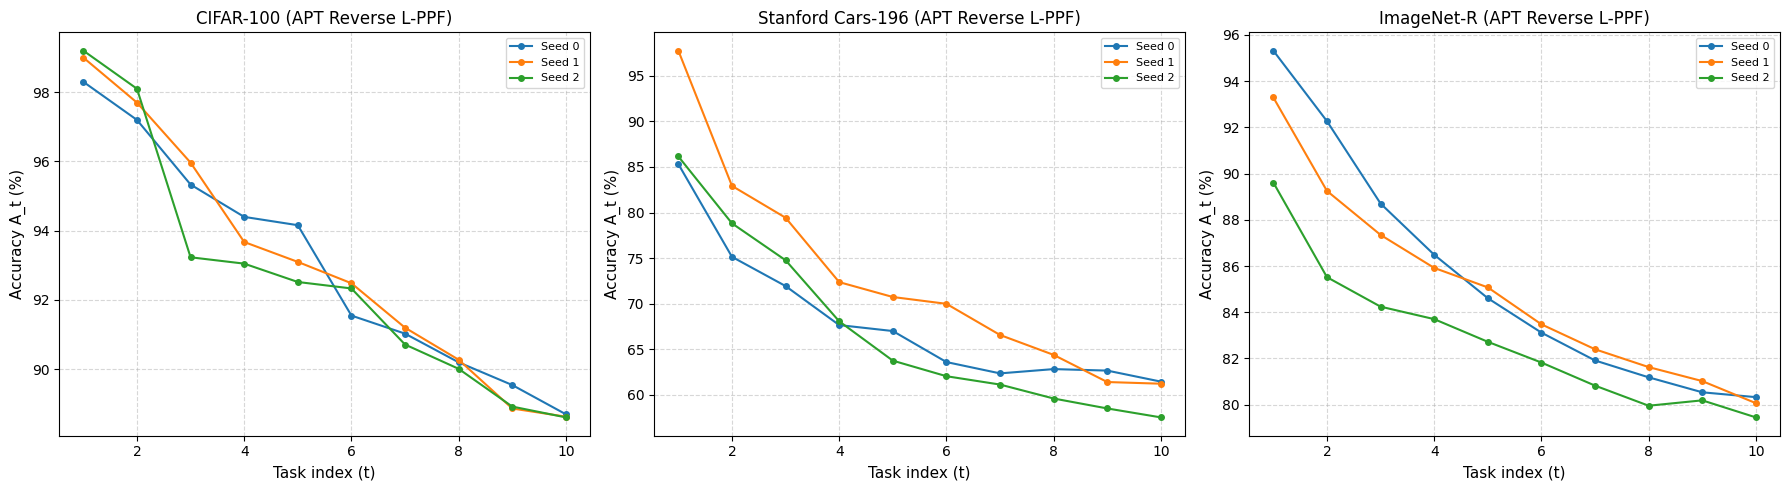

In [8]:
import matplotlib.pyplot as plt

master_rows = []

for ds_key, ds_results in ALL_RESULTS.items():
    ds_name = DATASET_CONFIGS[ds_key]["name"]
    for k, r in ds_results.items():
        master_rows.append({
            "Dataset": ds_name,
            "Experiment": k,
            "PPF Mode": r.get("ppf_mode", GLOBAL_CFG.get("ppf_mode", "reverse_layer_wise")),
            "Phase": r.get("phase", "val").upper(),
            "Seed": r.get("seed", 0),
            "Last Acc (%)": round(r.get("last", 0.0), 2),
            "Avg Acc (%)": round(r.get("avg", 0.0), 2),
            "Forgetting (%)": round(r.get("forgetting", 0.0), 2)
        })

df_all = pd.DataFrame(master_rows)
if not df_all.empty:
    print("📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (REVERSE L-PPF + HYBRID):", flush=True)
    display(df_all)
    df_all.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_reverse_lppf_detailed.csv"), index=False)

    print("\n🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT REVERSE L-PPF + HYBRID QUA CÁC DATASET (MEAN ± STD):", flush=True)
    master_stats = df_all.groupby(["Dataset", "Phase"]).agg({
        "Last Acc (%)": ["mean", "std"],
        "Avg Acc (%)": ["mean", "std"],
        "Forgetting (%)": ["mean", "std"]
    }).round(2)
    display(master_stats)
    master_stats.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_reverse_lppf_mean_std.csv"))

    # Vẽ biểu đồ so sánh đường cong A_t giữa các dataset
    n_datasets = len(ALL_RESULTS)
    fig, axes = plt.subplots(1, n_datasets, figsize=(6 * n_datasets, 5), squeeze=False)
    
    for i, (ds_key, ds_results) in enumerate(ALL_RESULTS.items()):
        ax = axes[0, i]
        ds_name = DATASET_CONFIGS[ds_key]["name"]
        for k, r in ds_results.items():
            a_t = r.get("A_t", [])
            if a_t:
                ax.plot(range(1, len(a_t) + 1), a_t, marker="o", markersize=4, label=f"Seed {r.get('seed')}")
        ax.set_xlabel("Task index (t)", fontsize=11)
        ax.set_ylabel("Accuracy A_t (%)", fontsize=11)
        ax.set_title(f"{ds_name} (APT Reverse L-PPF)", fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="best", fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(GLOBAL_CFG["base_out_dir"], "multi_dataset_reverse_lppf_curves.png"), dpi=150)
    plt.show()